In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

file_path = '/content/drive/MyDrive/projeto_mineracao/ProjetoDados/Dataset/Temp/guild_1201969909526175784.csv'

try:
    df = pd.read_csv(file_path)

    if 'content' in df.columns:

        # Estatísticas básicas
        print(f"Total de mensagens: {len(df)}")
        print(f"Mensagens com conteúdo: {df['content'].notna().sum()}")
        print(f"Mensagens vazias: {df['content'].isna().sum()}")

        # Exemplos de mensagens
        print("\nExemplos da coluna content:")
        display(df[['content']].dropna().head(10))

    else:
        print("Coluna content não encontrada.")
        print("Colunas disponíveis:", df.columns.tolist())

except Exception as e:
    print(f"Erro ao carregar o arquivo: {e}")

Total de mensagens: 52126
Mensagens com conteúdo: 51632
Mensagens vazias: 494

Exemplos da coluna content:


,content
0,"me chamo Sara tenho 16 anos, eu estudo, moro e..."
1,"Oi, gente! Bom diakkkkk, resolvi tentar a sort..."
2,"Olá, meu nome é Martins, tenho 16 anos, puxo m..."
3,bom diaa!! qro encontrar uma companheira pra j...
4,"oii meu nome é ariel, sou um garoto gay. procu..."
5,"Oi Oi, podem me chamar de Gustavo mesmo, tenho..."
6,Nome: Mari\nGênero: Feminino\nSexualidade: Pan...
7,Olá! Pode me chamar de Sun. Estou aqui procura...
8,"✧˖° Olá! Me chamo Nicollas,\nmas pode me chama..."
9,❌


In [15]:
df.columns

Index(['id', 'channel_id', 'guild_id', 'timestamp', 'content', 'type',
       'author_id', 'author_username', 'author_nome_exibicao', 'foi_editada',
       'pinned', 'mention_everyone', 'eh_bot', 'n_mencoes', 'n_attachments',
       'n_embeds', 'tem_midia'],
      dtype='object')

In [16]:
import pandas as pd

# Exemplo de agrupamento para a Tabela 1
tabela_1 = df.groupby('guild_id').agg(
    n_canais=('channel_id', 'nunique'),
    n_mensagens=('id', 'count'),
    n_usuarios_unicos=('author_id', 'nunique'),
    primeira_msg=('timestamp', 'min'),
    ultima_msg=('timestamp', 'max'),
    media_caracteres_msg=('content', lambda x: x.str.len().mean()),
    dp_caracteres_msg=('content', lambda x: x.str.len().std()),
    n_anexos=('n_attachments', 'sum'),
    n_mencoes=('n_mencoes', 'sum')
).reset_index()

# Calculando meses de atividade e médias
tabela_1['primeira_msg'] = pd.to_datetime(tabela_1['primeira_msg'])
tabela_1['ultima_msg'] = pd.to_datetime(tabela_1['ultima_msg'])
tabela_1['meses_atividade'] = ((tabela_1['ultima_msg'] - tabela_1['primeira_msg']).dt.days / 30).round(1)

display(tabela_1)

,guild_id,n_canais,n_mensagens,n_usuarios_unicos,primeira_msg,ultima_msg,media_caracteres_msg,dp_caracteres_msg,n_anexos,n_mencoes,meses_atividade
0,1201969909526175784,17,52126,2306,2024-09-27 21:20:41.229000+00:00,2026-07-29 14:01:08.751000+00:00,78.987043,185.012753,752,19041,22.3


In [17]:
tabela_2 = df.groupby(['guild_id', 'channel_id']).agg(
    n_mensagens=('id', 'count'),
    n_usuarios_unicos=('author_id', 'nunique'),
    primeira_msg=('timestamp', 'min'),
    ultima_msg=('timestamp', 'max'),
    media_caracteres=('content', lambda x: x.str.len().mean()),
    n_anexos=('n_attachments', 'sum'),
    n_mencoes=('n_mencoes', 'sum')
).reset_index()

display(tabela_2)

,guild_id,channel_id,n_mensagens,n_usuarios_unicos,primeira_msg,ultima_msg,media_caracteres,n_anexos,n_mencoes
0,1201969909526175784,1201969910612496455,1,1,2025-08-04 02:20:50.063000+00:00,2025-08-04 02:20:50.063000+00:00,NaN,0,0
1,1201969909526175784,1201969910612496456,2,1,2025-08-09 03:01:29.512000+00:00,2025-08-09 03:01:41.559000+00:00,NaN,0,0
2,1201969909526175784,1286927578182975533,3838,163,2024-09-27 21:20:41.229000+00:00,2026-07-22 23:39:55.154000+00:00,21.444184,4,400
3,1201969909526175784,1403272443065532536,1904,97,2025-11-12 05:28:22.144000+00:00,2026-07-19 06:52:07.747000+00:00,16.982133,1,217
4,1201969909526175784,1403272723643240500,4,1,2026-06-27 18:08:58.216000+00:00,2026-06-27 18:17:51.390000+00:00,21.250000,0,0
5,1201969909526175784,1403274001966432307,1108,107,2025-12-01 02:39:35.998000+00:00,2026-07-29 02:40:48.430000+00:00,19.669982,2,116
6,1201969909526175784,1403274306720501892,25,1,2025-10-05 01:11:28.007000+00:00,2025-10-05 01:23:57.968000+00:00,25.920000,0,1
7,1201969909526175784,1403274952089665578,806,86,2025-08-15 17:17:51.426000+00:00,2026-06-21 22:57:27.707000+00:00,49.837469,0,127
8,1201969909526175784,1446357615553544222,746,53,2025-12-06 01:45:27.990000+00:00,2026-07-05 17:26:01.747000+00:00,23.691689,0,79
9,1201969909526175784,1456450956844859528,10852,1731,2026-01-02 01:05:00.612000+00:00,2026-07-29 13:40:55.649000+00:00,295.228090,1,2268


In [18]:
# Convertendo timestamp para datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Extraindo informações temporais
df['hora'] = df['timestamp'].dt.hour
df['dia_semana'] = df['timestamp'].dt.day_name()
df['ano_mes'] = df['timestamp'].dt.to_period('M')

# 1. Distribuição por Horário e Dia da Semana (para o Mapa de Calor)
heatmap_data = df.pivot_table(index='dia_semana', columns='hora', values='id', aggfunc='count', fill_value=0)
display(heatmap_data)

# 2. Evolução Mensal
evolucao_mensal = df.groupby('ano_mes').agg(
    total_mensagens=('id', 'count'),
    usuarios_ativos=('author_id', 'nunique'),
    canais_ativos=('channel_id', 'nunique')
).reset_index()

display(evolucao_mensal)

/tmp/ipykernel_1885/2839636681.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['ano_mes'] = df['timestamp'].dt.to_period('M')


hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
dia_semana,,,,,,,,,,,,,,,,,,,,,
Friday,460,394,329,415,725,175,106,104,37,20,...,110,157,239,120,205,423,213,416,352,210
Monday,426,322,1579,1355,370,197,47,20,24,31,...,56,172,123,277,312,511,290,551,966,844
Saturday,448,764,439,397,344,368,94,41,19,8,...,263,205,194,328,392,283,401,608,352,433
Sunday,474,1072,644,672,314,244,226,82,39,37,...,77,151,121,178,385,225,310,461,572,335
Thursday,714,398,612,684,452,374,17,25,16,21,...,340,215,608,751,241,377,300,345,975,883
Tuesday,793,954,589,595,222,115,92,27,21,20,...,193,570,166,165,205,228,176,350,518,670
Wednesday,736,1243,724,1173,1008,285,94,73,229,32,...,75,507,451,223,172,210,233,457,338,530


,ano_mes,total_mensagens,usuarios_ativos,canais_ativos
0,2024-09,35,4,1
1,2024-10,423,17,1
2,2024-11,377,14,1
3,2024-12,343,13,1
4,2025-01,886,28,1
5,2025-02,117,10,1
6,2025-03,119,10,1
7,2025-04,30,8,1
8,2025-05,130,11,1
9,2025-07,18,3,1


/tmp/ipykernel_1885/2224822261.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['ano_mes'] = df['timestamp'].dt.to_period('M').astype(str)


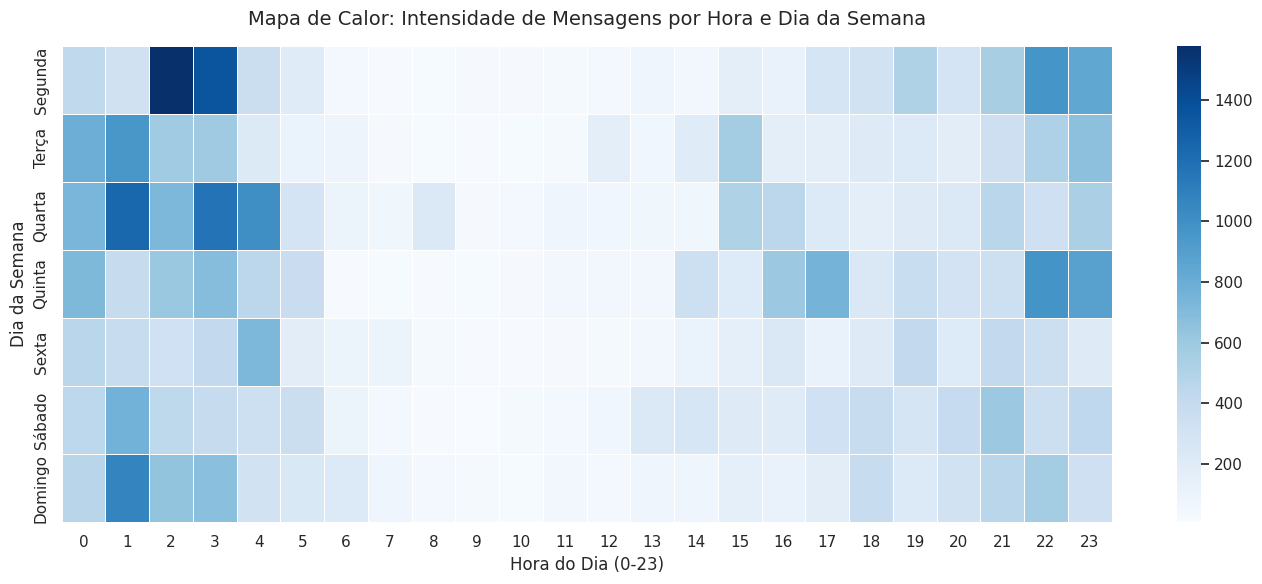

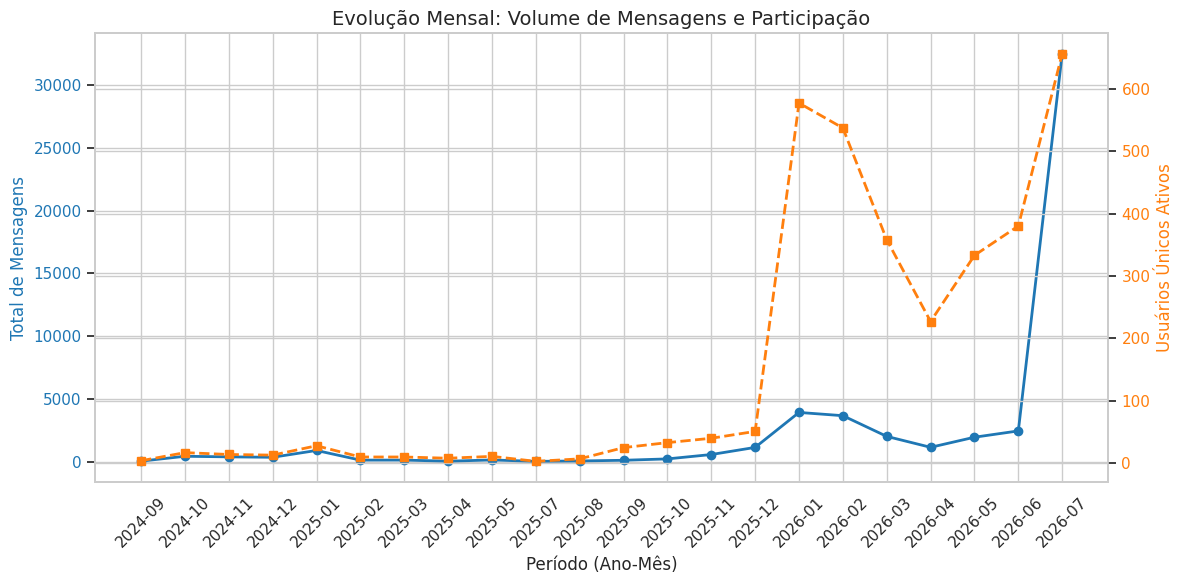

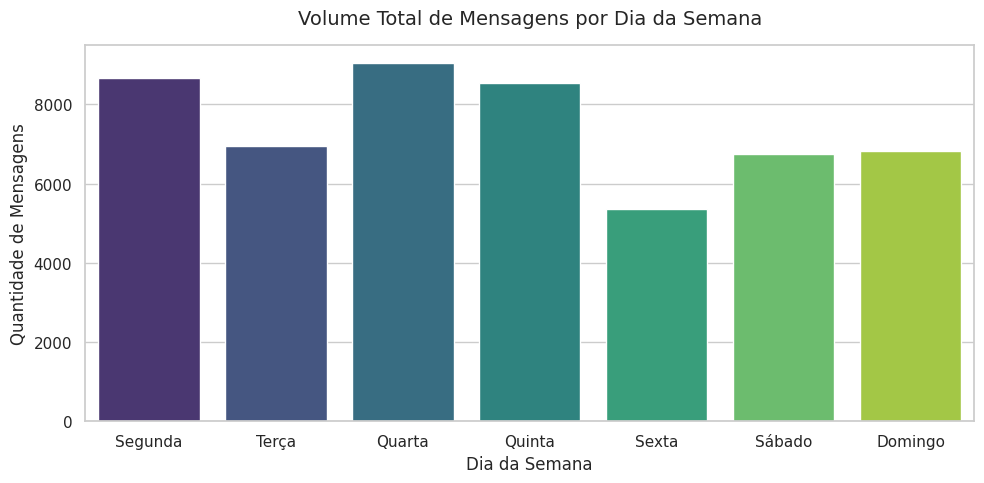

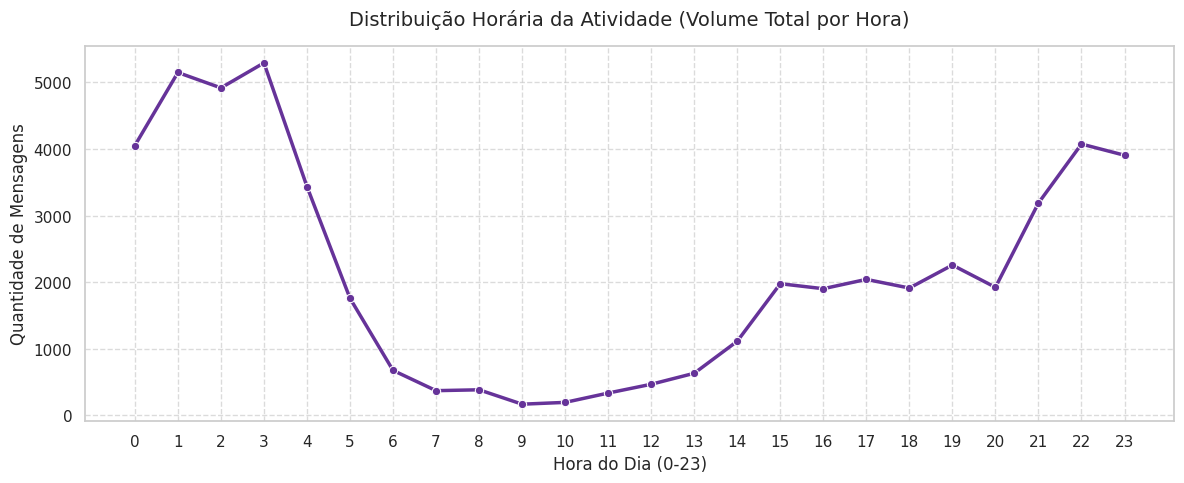

In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuração estética geral dos gráficos
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Garantindo que o timestamp está no formato datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Criando variáveis auxiliares de tempo
df['hora'] = df['timestamp'].dt.hour
df['dia_semana'] = df['timestamp'].dt.day_name()
df['ano_mes'] = df['timestamp'].dt.to_period('M').astype(str)

# Ordem correta dos dias da semana
dias_ordem = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
dias_pt = [
    'Segunda',
    'Terça',
    'Quarta',
    'Quinta',
    'Sexta',
    'Sábado',
    'Domingo',
]

# Mapeando para português para facilitar a visualização (opcional)
mapping_dias = dict(zip(dias_ordem, dias_pt))
df['dia_semana_pt'] = df['dia_semana'].map(mapping_dias)
dias_ordem_pt = [
    'Segunda',
    'Terça',
    'Quarta',
    'Quinta',
    'Sexta',
    'Sábado',
    'Domingo',
]

# ==========================================
# 1. MAPA DE CALOR: Horário vs Dia da Semana
# ==========================================
heatmap_data = df.pivot_table(
    index='dia_semana_pt',
    columns='hora',
    values='id',
    aggfunc='count',
    fill_value=0,
).reindex(dias_ordem_pt)

plt.figure(figsize=(14, 6))
sns.heatmap(
    heatmap_data, cmap='Blues', annot=False, fmt='d', cbar=True, linewidths=0.5
)
plt.title(
    'Mapa de Calor: Intensidade de Mensagens por Hora e Dia da Semana',
    fontsize=14,
    pad=15,
)
plt.xlabel('Hora do Dia (0-23)', fontsize=12)
plt.ylabel('Dia da Semana', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# 2. EVOLUÇÃO MENSAL (Mensagens e Usuários)
# ==========================================
evolucao = (
    df.groupby('ano_mes')
    .agg(
        total_mensagens=('id', 'count'),
        usuarios_ativos=('author_id', 'nunique'),
    )
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.set_xlabel('Período (Ano-Mês)', fontsize=12)
ax1.set_ylabel('Total de Mensagens', color='tab:blue', fontsize=12)
ax1.plot(
    evolucao['ano_mes'],
    evolucao['total_mensagens'],
    color='tab:blue',
    marker='o',
    linewidth=2,
    label='Mensagens',
)
ax1.tick_params(axis='y', labelcolor='tab:blue')
plt.xticks(rotation=45)

ax2 = ax1.twinx()
ax2.set_ylabel('Usuários Únicos Ativos', color='tab:orange', fontsize=12)
ax2.plot(
    evolucao['ano_mes'],
    evolucao['usuarios_ativos'],
    color='tab:orange',
    marker='s',
    linewidth=2,
    linestyle='--',
    label='Usuários',
)
ax2.tick_params(axis='y', labelcolor='tab:orange')

plt.title('Evolução Mensal: Volume de Mensagens e Participação', fontsize=14)
plt.tight_layout()
plt.show()

# ==========================================
# 3. DISTRIBUIÇÃO POR DIA DA SEMANA
# ==========================================
mensagens_dia = (
    df.groupby('dia_semana_pt')['id']
    .count()
    .reindex(dias_ordem_pt)
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x='dia_semana_pt',
    y='id',
    data=mensagens_dia,
    palette='viridis',
    hue='dia_semana_pt',
    legend=False,
)
plt.title(
    'Volume Total de Mensagens por Dia da Semana', fontsize=14, pad=15
)
plt.xlabel('Dia da Semana', fontsize=12)
plt.ylabel('Quantidade de Mensagens', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# 4. DISTRIBUIÇÃO POR HORÁRIO DO DIA
# ==========================================
mensagens_hora = df.groupby('hora')['id'].count().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(
    x='hora',
    y='id',
    data=mensagens_hora,
    marker='o',
    color='rebeccapurple',
    linewidth=2.5,
)
plt.title(
    'Distribuição Horária da Atividade (Volume Total por Hora)',
    fontsize=14,
    pad=15,
)
plt.xlabel('Hora do Dia (0-23)', fontsize=12)
plt.ylabel('Quantidade de Mensagens', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Total de Mensagens: 52126
Mensagens com Menções: 18730
Proporção de Mensagens Interativas (P_interativas): 35.93%

--- Métricas da Rede ---
Número de Nós (Usuários na rede): 30
Número de Arestas (Conexões): 406
Densidade da Rede: 0.9333


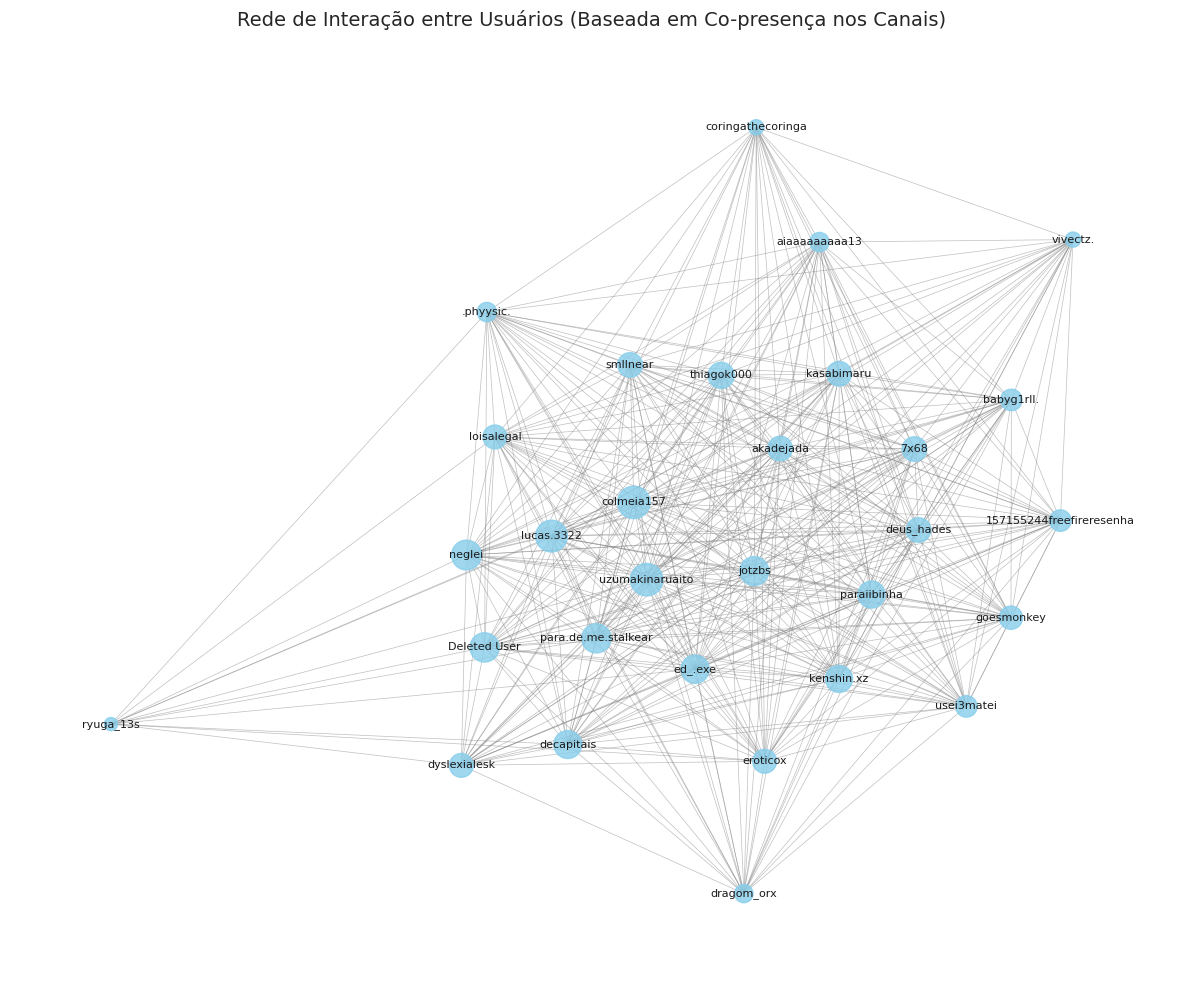

In [20]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns

# Garantindo que o DataFrame possui as colunas necessárias
# (Exemplo considerando 'author_id', 'author_username', 'n_mencoes', 'guild_id')

# ==========================================
# 1. CÁLCULO DA PROPORÇÃO DE MENSAGENS INTERATIVAS
# ==========================================
total_mensagens = len(df)
# Considerando mensagens com menções (ou filtrando por respostas se houver coluna específica)
msgs_com_mencoes = df[df['n_mencoes'] > 0].shape[0]

p_interativas = (
    (msgs_com_mencoes / total_mensagens) * 100 if total_mensagens > 0 else 0
)

print(f'Total de Mensagens: {total_mensagens}')
print(f'Mensagens com Menções: {msgs_com_mencoes}')
print(f'Proporção de Mensagens Interativas (P_interativas): {p_interativas:.2f}%')

# ==========================================
# 2. CONSTRUÇÃO DA REDE DE INTERAÇÃO (Social Network Analysis)
# ==========================================
# Para este exemplo, vamos criar uma rede de co-participação ou menções por canal/servidor.
# Se houver uma coluna de menções detalhadas, você pode extrair pares (Remetente -> Mencionado).
# Aqui simulamos a criação de arestas baseadas em interações no mesmo canal (frequência de postagem conjunta)
# ou conexões diretas caso o dataset possua IDs de quem está respondendo.

# Criando um grafo direcionado ou não-direcionado
G = nx.Graph()

# Exemplo simplificado: Adicionando nós (Usuários) e arestas baseadas em atividade no mesmo canal
# (Caso tenha pares de menções extraídos, adicione as arestas diretamente com G.add_edge(autor, mencionado, weight=...))

top_usuarios = df['author_username'].value_counts().head(30).index.tolist()
df_top = df[df['author_username'].isin(top_usuarios)]

# Adicionando arestas com base na participação no mesmo canal (proxy de interação)
for channel_id, grupo in df_top.groupby('channel_id'):
  autores = grupo['author_username'].unique()
  for i in range(len(autores)):
    for j in range(i + 1, len(autores)):
      u1, u2 = autores[i], autores[j]
      if G.has_edge(u1, u2):
        G[u1][u2]['weight'] += 1
      else:
        G.add_edge(u1, u2, weight=1)

# ==========================================
# 3. MÉTRICAS DE REDE COMPLEXA
# ==========================================
# Grau dos nós
grau = dict(G.degree())
# Grau ponderado (considerando o peso das arestas)
grau_ponderado = dict(G.degree(weight='weight'))
# Centralidade de intermediação
betweenness = nx.betweenness_centrality(G, weight='weight')
# Densidade da rede
densidade = nx.density(G)

print(f'\n--- Métricas da Rede ---')
print(f'Número de Nós (Usuários na rede): {G.number_of_nodes()}')
print(f'Número de Arestas (Conexões): {G.number_of_edges()}')
print(f'Densidade da Rede: {densidade:.4f}')

# ==========================================
# 4. VISUALIZAÇÃO GRÁFICA DA REDE
# ==========================================
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, k=0.15, seed=42)  # Algoritmo de posicionamento

# Definindo tamanho dos nós com base no grau ponderado
tamanho_nos = [v * 5 for v in grau_ponderado.values()]

nx.draw_networkx_nodes(
    G, pos, node_size=tamanho_nos, node_color='skyblue', alpha=0.8
)
nx.draw_networkx_edges(G, pos, width=0.5, alpha=0.5, edge_color='gray')
nx.draw_networkx_labels(G, pos, font_size=8, font_family='sans-serif')

plt.title(
    'Rede de Interação entre Usuários (Baseada em Co-presença nos Canais)',
    fontsize=14,
    pad=15,
)
plt.axis('off')
plt.tight_layout()
plt.show()

Total de arquivos de guilda encontrados: 100


/tmp/ipykernel_1885/4156218307.py:29: DtypeWarning: Columns (4,8) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(arquivo)


Dataset mestre consolidado com sucesso! Total de linhas: 13455755


/tmp/ipykernel_1885/4156218307.py:47: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['ano_mes'] = df['timestamp'].dt.to_period('M').astype(str)



Tabelas exportadas com sucesso para: /content/drive/MyDrive/projeto_mineracao/ProjetoDados/Resultados_Analises/


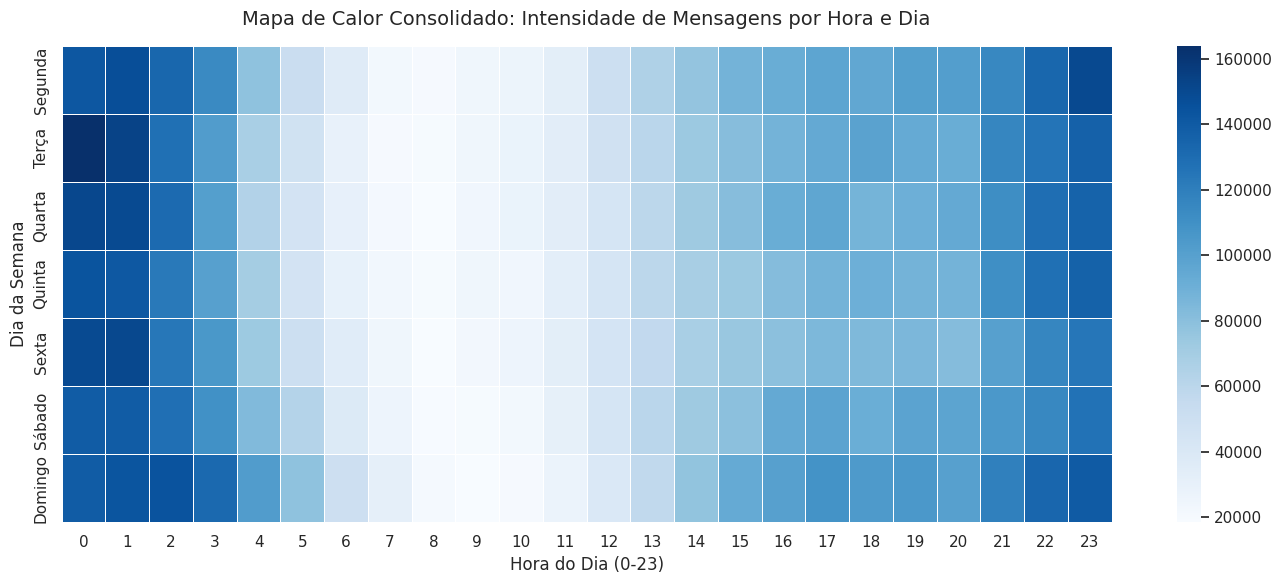

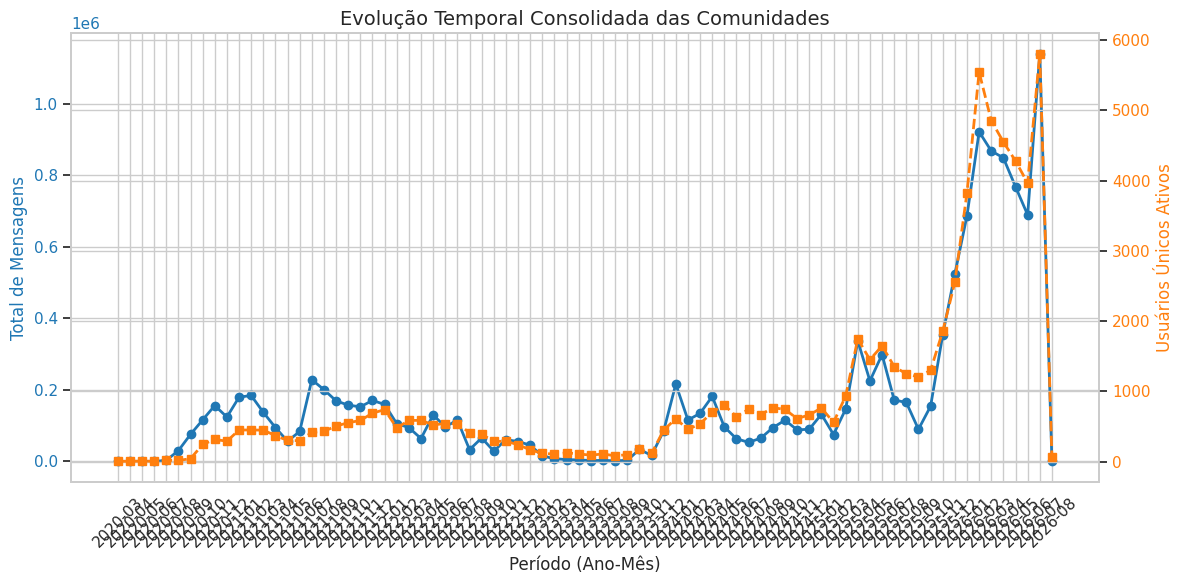

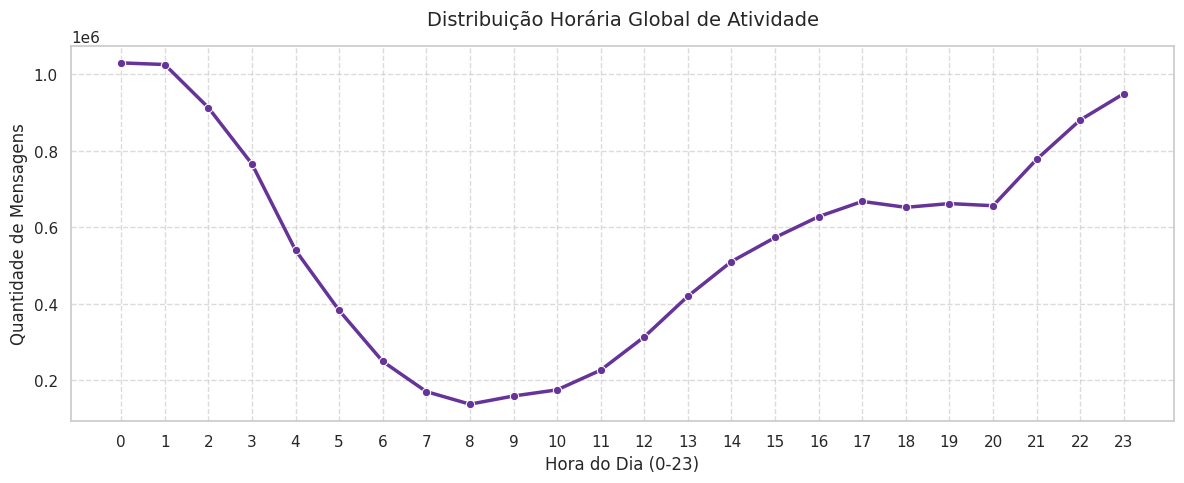

In [21]:
import glob
import os
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import seaborn as sns

# Configuração estética dos gráficos
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# ==========================================
# 1. CARREGAMENTO E CONSOLIDAÇÃO DOS 100 ARQUIVOS CSV
# ==========================================
# Caminho da pasta no Google Drive conforme a sua estrutura
pasta_path = (
    '/content/drive/MyDrive/projeto_mineracao/ProjetoDados/Dataset/Temp/'
)
padrao_busca = os.path.join(pasta_path, 'guild_*.csv')

arquivos_csv = glob.glob(padrao_busca)
print(f'Total de arquivos de guilda encontrados: {len(arquivos_csv)}')

# Lista para armazenar os dataframes individuais
lista_dfs = []

for arquivo in arquivos_csv:
  try:
    df_temp = pd.read_csv(arquivo)
    lista_dfs.append(df_temp)
  except Exception as e:
    print(f'Erro ao ler o arquivo {arquivo}: {e}')

# Consolidando todos os dados em um único DataFrame mestre
if lista_dfs:
  df = pd.concat(lista_dfs, ignore_index=True)
  print(f'Dataset mestre consolidado com sucesso! Total de linhas: {len(df)}')
else:
  raise ValueError('Nenhum dado foi carregado. Verifique o caminho da pasta.')

# ==========================================
# 2. PRÉ-PROCESSAMENTO DAS VARIÁVEIS TEMPORAIS
# ==========================================
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hora'] = df['timestamp'].dt.hour
df['dia_semana'] = df['timestamp'].dt.day_name()
df['ano_mes'] = df['timestamp'].dt.to_period('M').astype(str)

# Mapeamento dos dias para o português
dias_ordem = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
dias_pt = [
    'Segunda',
    'Terça',
    'Quarta',
    'Quinta',
    'Sexta',
    'Sábado',
    'Domingo',
]
mapping_dias = dict(zip(dias_ordem, dias_pt))
df['dia_semana_pt'] = df['dia_semana'].map(mapping_dias)
dias_ordem_pt = [
    'Segunda',
    'Terça',
    'Quarta',
    'Quinta',
    'Sexta',
    'Sábado',
    'Domingo',
]

# ==========================================
# 3. GERAÇÃO DAS TABELAS ANALÍTICAS
# ==========================================

# Tabela 1: Caracterização Geral dos Servidores (Guildas)
tabela_servidores = (
    df.groupby('guild_id')
    .agg(
        n_canais=('channel_id', 'nunique'),
        n_mensagens=('id', 'count'),
        n_usuarios_unicos=('author_id', 'nunique'),
        primeira_msg=('timestamp', 'min'),
        ultima_msg=('timestamp', 'max'),
        media_caracteres=('content', lambda x: x.str.len().mean()),
        dp_caracteres=('content', lambda x: x.str.len().std()),
        n_anexos=('n_attachments', 'sum'),
        n_mencoes=('n_mencoes', 'sum'),
    )
    .reset_index()
)

# Tabela 2: Caracterização dos Canais
tabela_canais = (
    df.groupby(['guild_id', 'channel_id'])
    .agg(
        n_mensagens=('id', 'count'),
        n_usuarios_unicos=('author_id', 'nunique'),
        primeira_msg=('timestamp', 'min'),
        ultima_msg=('timestamp', 'max'),
        media_caracteres=('content', lambda x: x.str.len().mean()),
        n_anexos=('n_attachments', 'sum'),
        n_mencoes=('n_mencoes', 'sum'),
    )
    .reset_index()
)

# Tabela de Evolução Mensal
tabela_evolucao = (
    df.groupby('ano_mes')
    .agg(
        total_mensagens=('id', 'count'),
        usuarios_ativos=('author_id', 'nunique'),
        canais_ativos=('channel_id', 'nunique'),
    )
    .reset_index()
)

# Salvando as tabelas geradas em formato CSV no Google Drive
pasta_saida = (
    '/content/drive/MyDrive/projeto_mineracao/ProjetoDados/Resultados_Analises/'
)
os.makedirs(pasta_saida, exist_ok=True)

tabela_servidores.to_csv(
    os.path.join(pasta_saida, 'tabela_1_servidores.csv'), index=False
)
tabela_canais.to_csv(
    os.path.join(pasta_saida, 'tabela_2_canais.csv'), index=False
)
tabela_evolucao.to_csv(
    os.path.join(pasta_saida, 'tabela_evolucao_mensal.csv'), index=False
)
print(f'\nTabelas exportadas com sucesso para: {pasta_saida}')

# ==========================================
# 4. GERAÇÃO DAS VISUALIZAÇÕES GRÁFICAS
# ==========================================

# Gráfico 1: Mapa de Calor (Horário vs Dia da Semana)
heatmap_data = df.pivot_table(
    index='dia_semana_pt',
    columns='hora',
    values='id',
    aggfunc='count',
    fill_value=0,
).reindex(dias_ordem_pt)

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_data, cmap='Blues', cbar=True, linewidths=0.5)
plt.title(
    'Mapa de Calor Consolidado: Intensidade de Mensagens por Hora e Dia',
    fontsize=14,
    pad=15,
)
plt.xlabel('Hora do Dia (0-23)', fontsize=12)
plt.ylabel('Dia da Semana', fontsize=12)
plt.tight_layout()
plt.show()

# Gráfico 2: Evolução Mensal (Mensagens e Usuários)
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.set_xlabel('Período (Ano-Mês)', fontsize=12)
ax1.set_ylabel('Total de Mensagens', color='tab:blue', fontsize=12)
ax1.plot(
    tabela_evolucao['ano_mes'],
    tabela_evolucao['total_mensagens'],
    color='tab:blue',
    marker='o',
    linewidth=2,
    label='Mensagens',
)
ax1.tick_params(axis='y', labelcolor='tab:blue')
plt.xticks(rotation=45)

ax2 = ax1.twinx()
ax2.set_ylabel('Usuários Únicos Ativos', color='tab:orange', fontsize=12)
ax2.plot(
    tabela_evolucao['ano_mes'],
    tabela_evolucao['usuarios_ativos'],
    color='tab:orange',
    marker='s',
    linewidth=2,
    linestyle='--',
    label='Usuários',
)
ax2.tick_params(axis='y', labelcolor='tab:orange')
plt.title('Evolução Temporal Consolidada das Comunidades', fontsize=14)
plt.tight_layout()
plt.show()

# Gráfico 3: Distribuição por Horário do Dia
mensagens_hora = df.groupby('hora')['id'].count().reset_index()
plt.figure(figsize=(12, 5))
sns.lineplot(
    x='hora',
    y='id',
    data=mensagens_hora,
    marker='o',
    color='rebeccapurple',
    linewidth=2.5,
)
plt.title('Distribuição Horária Global de Atividade', fontsize=14, pad=15)
plt.xlabel('Hora do Dia (0-23)', fontsize=12)
plt.ylabel('Quantidade de Mensagens', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1885/1497829491.py:22: DtypeWarning: Columns (4,8) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(arquivo)


Tabelas de conteúdo salvas com sucesso em: /content/drive/MyDrive/projeto_mineracao/ProjetoDados/Resultados_Analises/


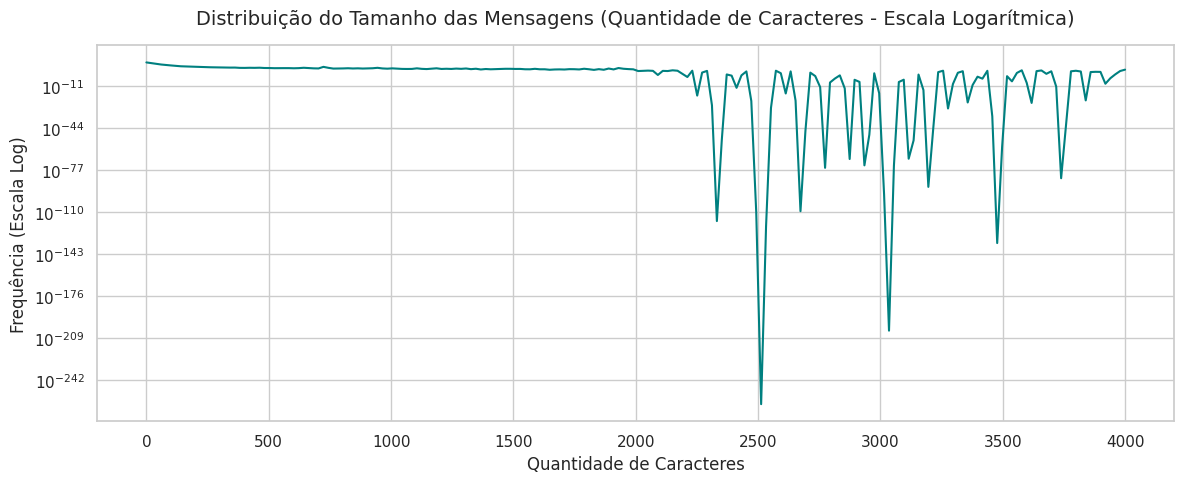

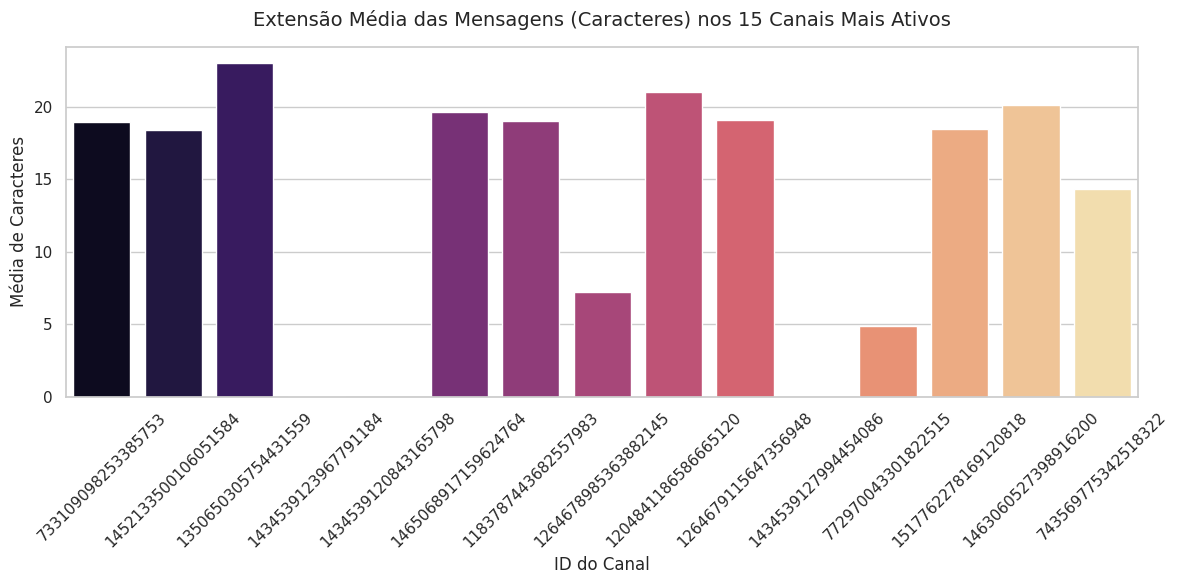

In [ ]:
import glob
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from wordcloud import WordCloud

# ==========================================
# 1. CARREGAMENTO E CONSOLIDAÇÃO DOS CSVs
# ==========================================
pasta_path = (
    '/content/drive/MyDrive/projeto_mineracao/ProjetoDados/Dataset/Temp/'
)
padrao_busca = os.path.join(pasta_path, 'guild_*.csv')
arquivos_csv = glob.glob(padrao_busca)

lista_dfs = []
for arquivo in arquivos_csv:
  try:
    df_temp = pd.read_csv(arquivo)
    lista_dfs.append(df_temp)
  except Exception as e:
    print(f'Erro ao ler {arquivo}: {e}')

df = pd.concat(lista_dfs, ignore_index=True)

# ==========================================
# 2. PROCESSAMENTO DE MÉTRICAS DE CONTEÚDO
# ==========================================
# Garantindo string na coluna de conteúdo
df['content_clean'] = df['content'].fillna('').astype(str)

# Métricas de extensão
df['qtd_caracteres'] = df['content_clean'].str.len()
df['qtd_palavras'] = df['content_clean'].apply(lambda x: len(x.split()))

# Expressão regular para links e emojis
regex_url = r'https?://\S+|www\.\S+'
regex_emoji = r'[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF\U0001F680-\U0001F6FF\U0001F1E0-\U0001F1FF]'

df['tem_link'] = df['content_clean'].str.contains(regex_url, regex=True)
df['tem_emoji'] = df['content_clean'].str.contains(regex_emoji, regex=True)


# Função para identificar se a mensagem contém apenas emojis e espaços
def apenas_emoji(texto):
  texto_sem_espaco = texto.replace(' ', '')
  if not texto_sem_espaco:
    return False
  emojis_encontrados = re.findall(regex_emoji, texto_sem_espaco)
  return len(''.join(emojis_encontrados)) == len(texto_sem_espaco)


df['apenas_emoji'] = df['content_clean'].apply(apenas_emoji)

# ==========================================
# 3. CONSTRUÇÃO DA TABELA 4 (RESUMO CONSOLIDADO)
# ==========================================
total_msgs = len(df)
msgs_vazias = df[
    df['content'].isna() | (df['content_clean'].str.strip() == '')
].shape[0]
msgs_com_texto = total_msgs - msgs_vazias

tabela_conteudo = pd.DataFrame([{
    'Métrica': 'Total de Mensagens Analisadas',
    'Valor': total_msgs,
}, {
    'Métrica': 'Mensagens com Texto',
    'Valor': msgs_com_texto,
}, {
    'Métrica': 'Mensagens Vazias (Apenas Mídia/Anexo)',
    'Valor': msgs_vazias,
}, {
    'Métrica': 'Média de Caracteres por Mensagem',
    'Valor': round(df['qtd_caracteres'].mean(), 2),
}, {
    'Métrica': 'Mediana de Caracteres por Mensagem',
    'Valor': df['qtd_caracteres'].median(),
}, {
    'Métrica': 'Desvio-Padrão de Caracteres',
    'Valor': round(df['qtd_caracteres'].std(), 2),
}, {
    'Métrica': 'Média de Palavras por Mensagem',
    'Valor': round(df['qtd_palavras'].mean(), 2),
}, {
    'Métrica': 'Mensagens com Links (URLs)',
    'Valor': df['tem_link'].sum(),
}, {
    'Métrica': 'Mensagens com Emojis',
    'Valor': df['tem_emoji'].sum(),
}, {
    'Métrica': 'Mensagens Apenas com Emojis',
    'Valor': df['apenas_emoji'].sum(),
}, {
    'Métrica': 'Mensagens com Anexos',
    'Valor': df[df['n_attachments'] > 0].shape[0],
}])

# Comparativo da Extensão Média de Texto por Canal (Top 20 canais mais ativos)
tabela_canais_extensao = (
    df.groupby(['guild_id', 'channel_id'])
    .agg(
        total_mensagens=('id', 'count'),
        media_caracteres=('qtd_caracteres', 'mean'),
        mediana_caracteres=('qtd_caracteres', 'median'),
        media_palavras=('qtd_palavras', 'mean'),
    )
    .reset_index()
    .sort_values(by='total_mensagens', ascending=False)
)

# Exportando Tabelas em CSV para o Drive
pasta_saida = (
    '/content/drive/MyDrive/projeto_mineracao/ProjetoDados/Resultados_Analises/'
)
os.makedirs(pasta_saida, exist_ok=True)

tabela_conteudo.to_csv(
    os.path.join(pasta_saida, 'tabela_4_caracterizacao_conteudo.csv'),
    index=False,
)
tabela_canais_extensao.to_csv(
    os.path.join(pasta_saida, 'tabela_extensao_texto_por_canal.csv'), index=False
)

print(f'Tabelas de conteúdo salvas com sucesso em: {pasta_saida}')

# ==========================================
# 4. VISUALIZAÇÕES GRÁFICAS DO CONTEÚDO
# ==========================================

# Gráfico 1: Distribuição do Tamanho das Mensagens (Boxplot e Histograma em corte logarítmico)
plt.figure(figsize=(12, 5))
sns.histplot(
    df['qtd_caracteres'],
    bins=50,
    kde=True,
    color='teal',
    log_scale=(False, True),
)
plt.title(
    'Distribuição do Tamanho das Mensagens (Quantidade de Caracteres - Escala Logarítmica)',
    fontsize=14,
    pad=15,
)
plt.xlabel('Quantidade de Caracteres', fontsize=12)
plt.ylabel('Frequência (Escala Log)', fontsize=12)
plt.tight_layout()
plt.show()

# Gráfico 2: Comparação da Extensão Média de Texto entre os 15 Canais Mais Ativos
top_15_canais = tabela_canais_extensao.head(15).copy()
top_15_canais['channel_label'] = top_15_canais['channel_id'].astype(str)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_15_canais,
    x='channel_label',
    y='media_caracteres',
    palette='magma',
    hue='channel_label',
    legend=False,
)
plt.title(
    'Extensão Média das Mensagens (Caracteres) nos 15 Canais Mais Ativos',
    fontsize=14,
    pad=15,
)
plt.xlabel('ID do Canal', fontsize=12)
plt.ylabel('Média de Caracteres', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Gráfico 3: Nuvem de Palavras (WordCloud) Consolidada do Dataset
texto_completo = ' '.join(df['content_clean'].dropna())

# Removendo URLs da nuvem de palavras
texto_limpo_wc = re.sub(regex_url, '', texto_completo)

wc = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=150,
    colormap='viridis',
).generate(texto_limpo_wc)

plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Nuvem de Palavras — Termos Mais Frequentes nas Comunidades', fontsize=16, pad=15)
plt.tight_layout()
plt.show()